# Assignment 5: Comparing representations across two layers of a rotated MNIST network
Audrey and Kevin and Trinity

Every MNIST image is rotated by a random angle between 0° and 360°, and we keep each image's angle. We train a small MLP (784 → 256 → 64 → 10) to name the digit, then compare hidden layer 1 (256 units) with hidden layer 2 (64 units). Linear method: PCA. Nonlinear method: t-SNE. We also compare tuning curves and RDMs.

In [2]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
from torchvision import datasets, transforms
import torchvision.transforms.functional as TF
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torchvision import datasets
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import math
import random
from scipy.stats import spearmanr

torch.manual_seed(0); np.random.seed(0)
train = datasets.MNIST('data', train=True, download=True)
test = datasets.MNIST('data', train=False, download=True)

In [3]:
class RotatedMNIST(Dataset):
    def __init__(self, base_dataset, min_digit: int, max_digit: int, min_rotation_deg: float, max_rotation_deg: float):
        self.base_dataset = base_dataset # the original MNIST dataset
        self.min_rotation_deg = min_rotation_deg
        self.max_rotation_deg = max_rotation_deg

        # Filter dataset using max_digit:
        valid_indices = torch.where((base_dataset.targets >= min_digit) & (base_dataset.targets <= max_digit))[0]
        self.indices = valid_indices.tolist()

    def __len__(self):
        # Return the length of the filtered dataset, not the whole dataset:
        return len(self.indices)

    def __getitem__(self, idx):
        # Map the requested index to the actual index in the dataset:
        real_idx = self.indices[idx]

        # Retrieve the base image tensor and digit label:
        img_tensor, digit_label = self.base_dataset[real_idx]

        # Generate a random angle (0 to max_rotation parameter value)
        angle_deg = random.uniform(self.min_rotation_deg, self.max_rotation_deg)
        angle_rad = math.radians(angle_deg)

        # Rotate the image tensor
        img_rotated = TF.rotate(img_tensor, angle_deg, fill=0)

        img_tensor = TF.to_tensor(img_rotated)

        # Convert continuous radian angle into a 2-value tensor (Sin and Cos)
        # $$$ Not using currently, but may consider if it improves accuracy
        # sin_cos_target = torch.tensor([math.sin(angle_rad), math.cos(angle_rad)], dtype=torch.float32)

        return img_tensor, digit_label, angle_rad, angle_deg

In [4]:
train_data = RotatedMNIST(
    base_dataset=train, 
    min_digit=0, # Defaults to 0 if not found
    max_digit=9, # Defaults to 9 if not found
    min_rotation_deg=0,
    max_rotation_deg=360
)
    
test_data = RotatedMNIST(
    base_dataset=test, 
    min_digit=0,
    max_digit=9,
    min_rotation_deg=0,
    max_rotation_deg=360
)

In [12]:
class TwoHeadedNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.body = nn.Sequential(nn.Flatten(),
                                  nn.Linear(784, 256),
                                  nn.ReLU(),
                                  nn.Linear(256, 64),
                                  nn.ReLU())
        self.digit_head = nn.Linear(64, 10)
        self.angle_head = nn.Linear(64, 24)

    def forward(self, x):
        h = self.body(x)
        return self.digit_head(h), self.angle_head(h)

In [14]:
net = TwoHeadedNN()
opt = torch.optim.Adam(net.parameters(), lr=1e-3)

train_loader = DataLoader(train_data, batch_size=128, shuffle=True)
test_loader = DataLoader(test_data, batch_size=1000, shuffle=False)

for epoch in range(8):
    net.train()
    for images, digit_labels, _, angles in train_loader:
        angle_labels = (angles // 15).long().clamp(max=23)
        opt.zero_grad()
        digit_output, angle_output = net(images)
        loss = F.cross_entropy(digit_output, digit_labels) + F.cross_entropy(angle_output, angle_labels)
        loss.backward()
        opt.step()

net.eval()
all_X, all_y, all_angles = [], [], []
with torch.no_grad():
    for images, labels, _, angles in test_loader:
        all_X.append(images)
        all_y.append(labels)
        all_angles.append(angles)

X = torch.cat(all_X, dim=0)
y = torch.cat(all_y, dim=0).numpy()
angle = torch.cat(all_angles, dim=0).numpy()

angle_class = (angle // 15).astype(int).clip(max=23)
angle_bin   = (angle // 30).astype(int)

with torch.no_grad():
    digit_out, angle_out = net(X)
    digit_pred = digit_out.argmax(1).numpy()
    angle_pred = angle_out.argmax(1).numpy()

    print('Test Digit Accuracy:', (digit_pred == y).mean())
    print('Test Rotation Accuracy:', (angle_pred == angle_class).mean())

    diff = np.abs(angle_pred - angle_class); diff = np.minimum(diff, 24 - diff)
    print('Rotation within ±15°:  ', (diff <= 1).mean())
    
    h1 = net.body[:3](X).numpy() # Flatten -> Linear(256) -> ReLU
    h2 = net.body[:5](X).numpy() # ... -> Linear(64) -> ReLU

layers = {'Layer 1 (256 units)': h1, 'Layer 2 (64 units)': h2}

Test Digit Accuracy: 0.901
Test Rotation Accuracy: 0.689
Rotation within ±15°:   0.9355


In [15]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import cross_val_predict

target = np.c_[np.sin(np.deg2rad(angle)), np.cos(np.deg2rad(angle))]

for name, a in layers.items():

    p = cross_val_predict(Ridge(1.0), a, target, cv=5)
    pred_angle = np.rad2deg(np.arctan2(p[:, 0], p[:, 1])) % 360
    err = np.abs(pred_angle - angle); err = np.minimum(err, 360 - err)

    print(f'{name}: mean angle error = {err.mean():.1f}°, within 30° = {(err < 30).mean():.3f}')


Layer 1 (256 units): mean angle error = 17.3°, within 30° = 0.848
Layer 2 (64 units): mean angle error = 18.3°, within 30° = 0.820


  0– 30°: 0.904
 30– 60°: 0.916
 60– 90°: 0.878
 90–120°: 0.897
120–150°: 0.888
150–180°: 0.895
180–210°: 0.914
210–240°: 0.910
240–270°: 0.888
270–300°: 0.898
300–330°: 0.894
330–360°: 0.912


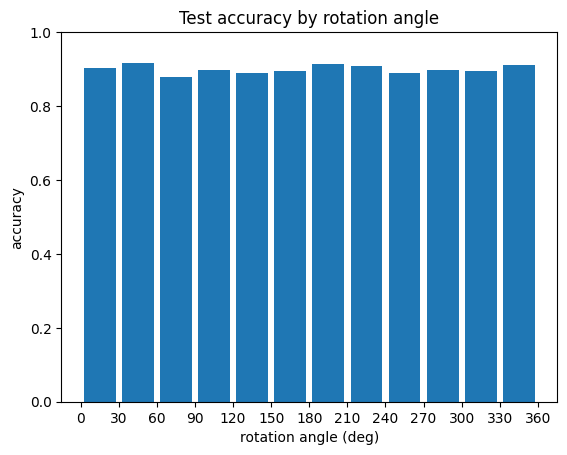

In [11]:
with torch.no_grad():
    pred = net(X)[0].argmax(1).numpy()
correct = pred == y

# accuracy per 30° bin
bin_acc = np.array([correct[angle_bin == k].mean() for k in range(12)])
for k, acc in enumerate(bin_acc):
    print(f'{30*k:3d}–{30*(k+1):3d}°: {acc:.3f}')

plt.bar(np.arange(12) * 30 + 15, bin_acc, width=25)
plt.xticks(range(0, 361, 30))
plt.xlabel('rotation angle (deg)'); plt.ylabel('accuracy')
plt.ylim(0, 1); plt.title('Test accuracy by rotation angle')
plt.show()


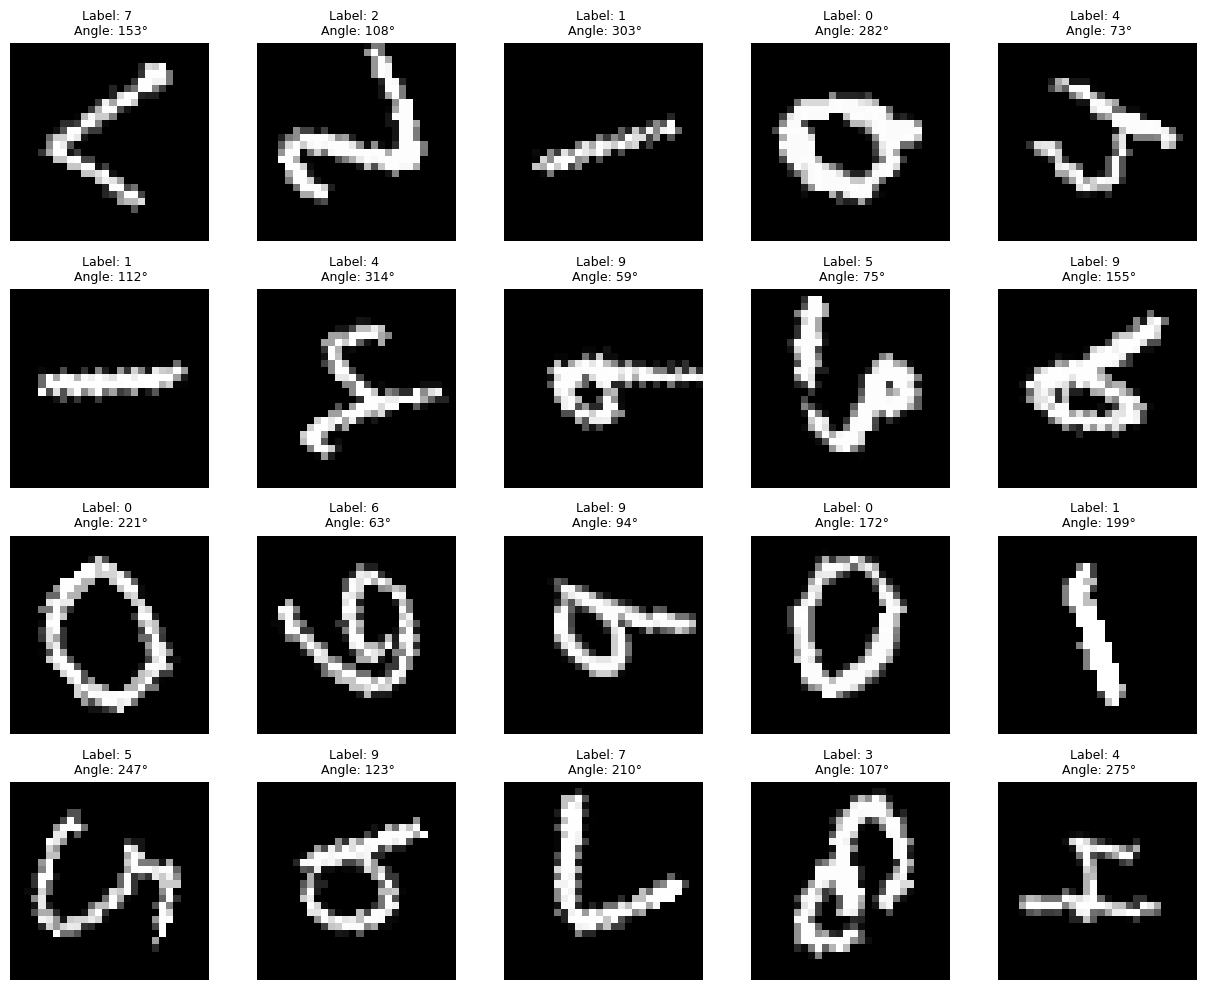

In [16]:
import math

def show_large_grid(dataset, n=25, max_cols=5):
    """Dynamically sizes the figure grid so images never shrink below a readable size."""
    n = min(n, len(dataset))
    cols = min(n, max_cols)
    rows = math.ceil(n / cols)

    # Scale figure dimensions dynamically (e.g., 2.5 inches per image tile)
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 2.5, rows * 2.5))

    # Handle edge case where axes might be a single Axes object or 1D array
    if n == 1:
        axes = np.array([axes])
    else:
        axes = axes.flatten()

    for i in range(n):
        img_tensor, digit_label, _, angle_deg = dataset[i]
        img_np = img_tensor.squeeze(0).numpy()

        axes[i].imshow(img_np, cmap='gray')
        axes[i].set_title(f"Label: {digit_label} \n Angle: {angle_deg:.0f}°", fontsize=9)
        axes[i].axis('off')

    # Turn off unused axes if grid has empty slots
    for j in range(n, len(axes)):
        axes[j].axis('off')

    plt.tight_layout()
    plt.show()

# Example: Display 20 images cleanly in a 5-column layout
show_large_grid(test_data, n=20, max_cols=5)

## Linear (PCA) and nonlinear (t-SNE) views of each layer

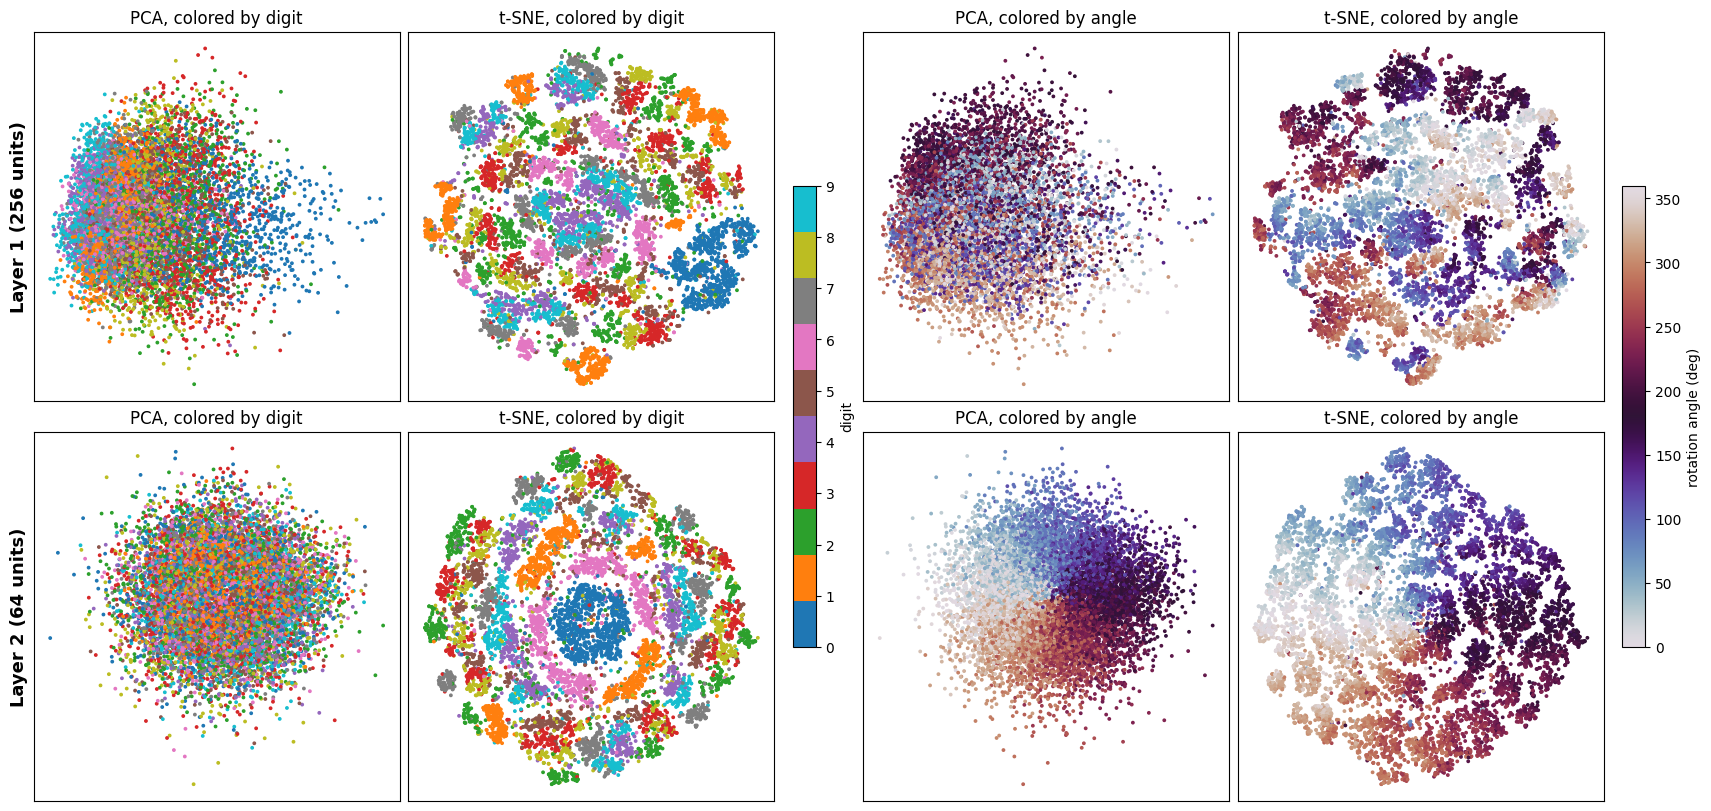

In [17]:
fig, ax = plt.subplots(2, 4, figsize=(17, 8), layout='constrained')
for r, (name, a) in enumerate(layers.items()):
   for c, (emb, method) in enumerate([(PCA(2).fit_transform(a), 'PCA'),
                                      (TSNE(2, random_state=0, init='pca').fit_transform(a), 't-SNE')]):
       s1 = ax[r, c].scatter(*emb.T, c=y, cmap='tab10', s=3)
       s2 = ax[r, c + 2].scatter(*emb.T, c=angle, cmap='twilight', vmin=0, vmax=360, s=3)
       ax[r, c].set(title=f'{method}, colored by digit', xticks=[], yticks=[])
       ax[r, c + 2].set(title=f'{method}, colored by angle', xticks=[], yticks=[])
   ax[r, 0].set_ylabel(name, fontsize=13, fontweight='bold')
fig.colorbar(s1, ax=ax[:, 1], label='digit', shrink=0.6)
fig.colorbar(s2, ax=ax[:, 3], label='rotation angle (deg)', shrink=0.6)
plt.show()

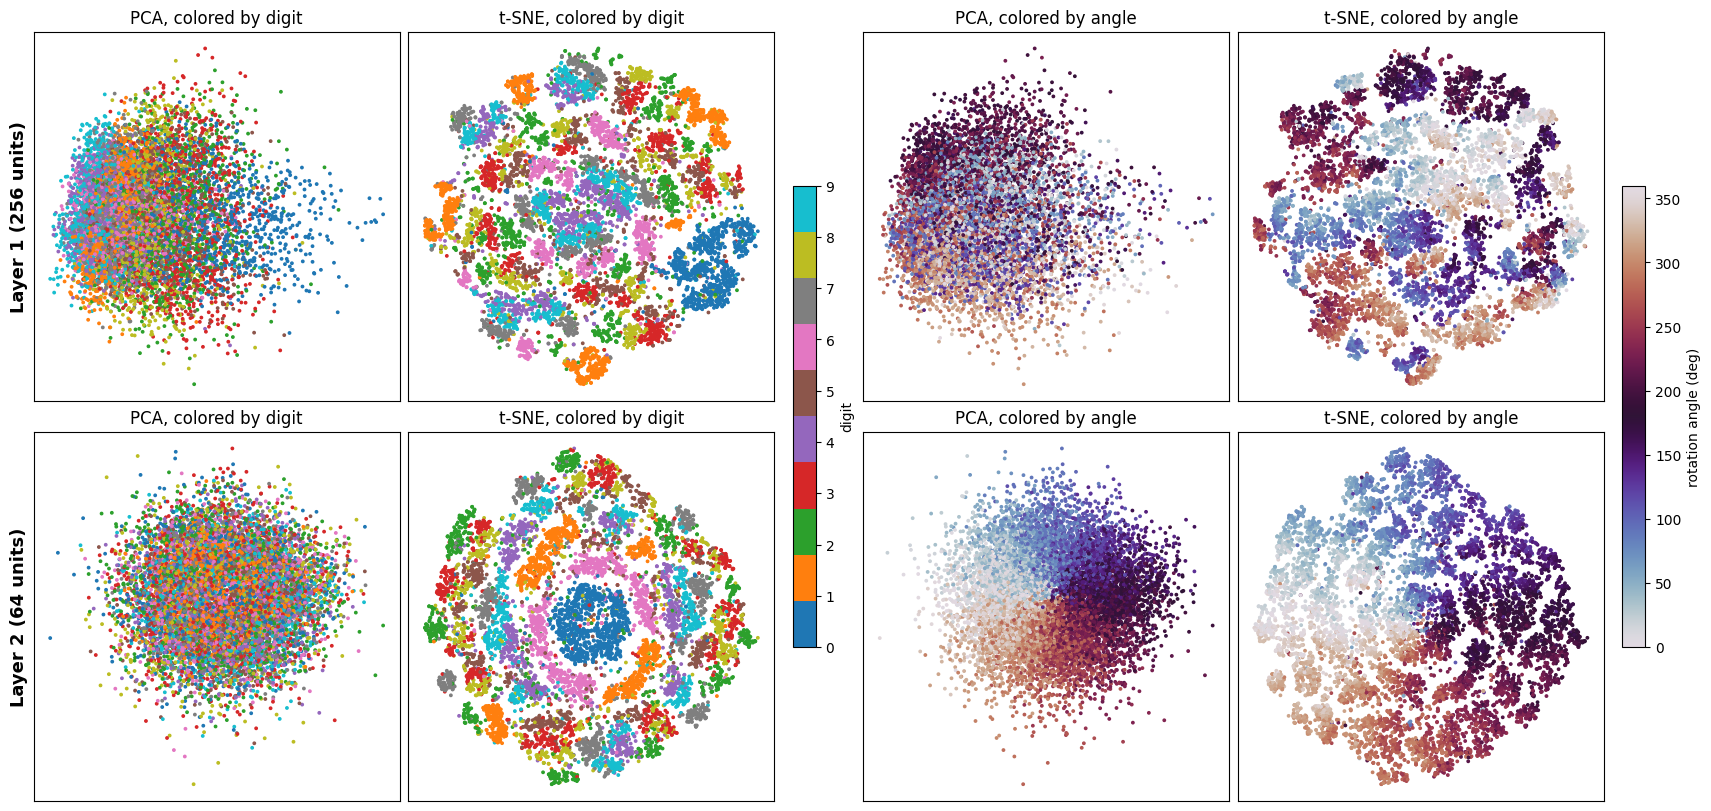

In [18]:
fig, ax = plt.subplots(2, 4, figsize=(17, 8), layout='constrained')
for r, (name, a) in enumerate(layers.items()):
    for c, (emb, method) in enumerate([(PCA(2).fit_transform(a), 'PCA'),
                                       (TSNE(2, random_state=0, init='pca').fit_transform(a), 't-SNE')]):
        s1 = ax[r, c].scatter(*emb.T, c=y, cmap='tab10', s=3)
        s2 = ax[r, c + 2].scatter(*emb.T, c=angle, cmap='twilight', vmin=0, vmax=360, s=3)
        ax[r, c].set(title=f'{method}, colored by digit', xticks=[], yticks=[])
        ax[r, c + 2].set(title=f'{method}, colored by angle', xticks=[], yticks=[])
    ax[r, 0].set_ylabel(name, fontsize=13, fontweight='bold')
fig.colorbar(s1, ax=ax[:, 1], label='digit', shrink=0.6)
fig.colorbar(s2, ax=ax[:, 3], label='rotation angle (deg)', shrink=0.6)
plt.show()

## Tuning curves for digit and rotation angle

In [19]:
#def tuning(a, labels):
#    m = np.array([a[labels == k].mean(0) for k in np.unique(labels)])
#    act = m.max(0) > 1e-6
#    m = m[:, act]
#    best, rest = m.max(0), (m.sum(0) - m.max(0)) / (len(m) - 1)
#    explained = m.var(0) / a[:, act].var(0)
#    return m, ((best - rest) / (best + rest)).mean(), explained.mean()

#fig, ax = plt.subplots(2, 2, figsize=(13, 8), layout='constrained')
#stats = {}
#for r, (name, a) in enumerate(layers.items()):
#    md, sel_d, var_d = tuning(a, y)
#    ma, sel_a, var_a = tuning(a, angle_bin)
#    for c, (m, label, ticks) in enumerate([(md, 'digit', range(10)), (ma, 'rotation angle (30 deg bins)', range(12))]):
#        m = m[:, np.argsort(m.argmax(0))]
#        ax[r, c].imshow(m / m.max(0), aspect='auto', cmap='viridis')
#        ax[r, c].set(title=f'{name}: tuning to {label.split(" (")[0]}', xlabel='unit (sorted by preference)', ylabel=label, yticks=ticks)
#    ax[r, 1].set_yticklabels([f'{30 * k}' for k in range(12)])
#    stats[name] = {'active units': md.shape[1], 'digit selectivity': sel_d, 'angle selectivity': sel_a,
#                   'variance explained by digit': var_d, 'variance explained by angle': var_a}
#plt.show()
#for name, s in stats.items():
#    print(name, {k: round(float(v), 3) for k, v in s.items()})

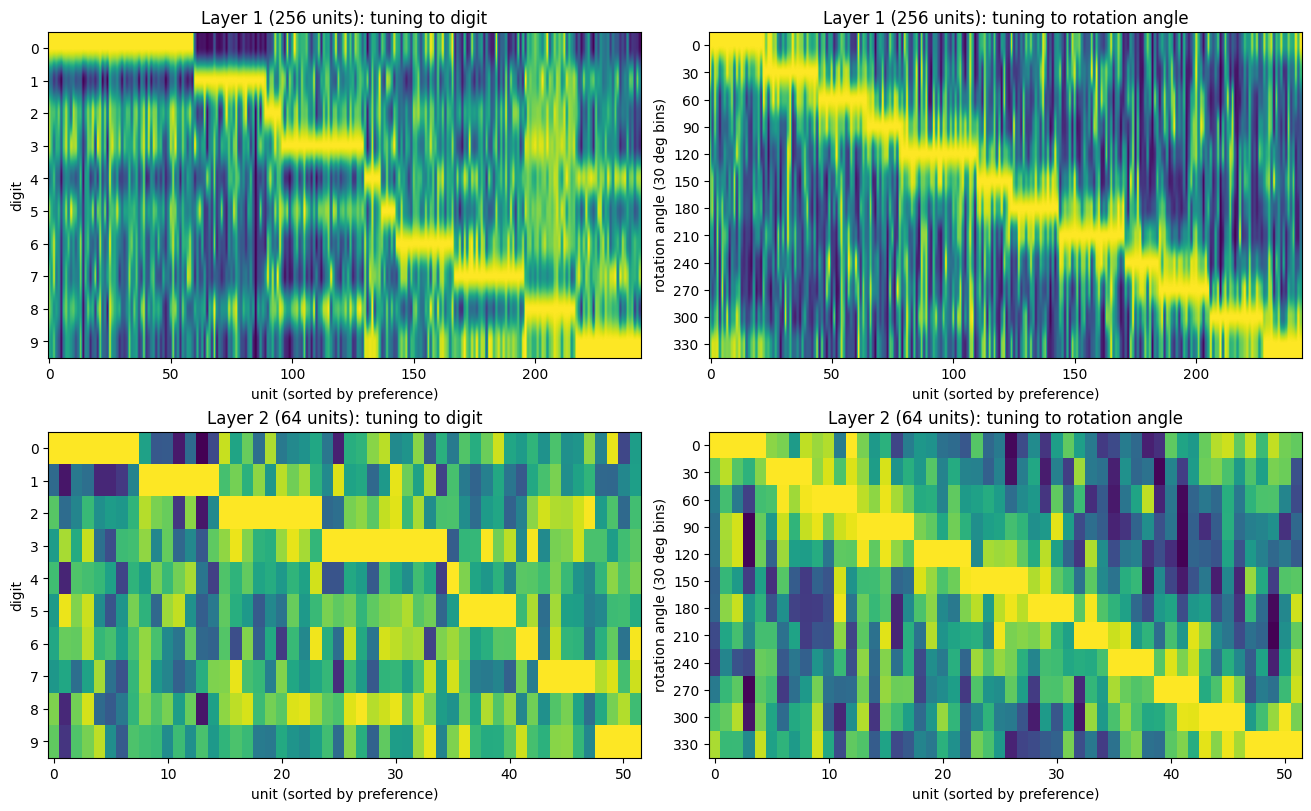

Layer 1 (256 units) {'active units': 244.0, 'digit selectivity': 0.324, 'angle selectivity': 0.372, 'variance explained by digit': 0.091, 'variance explained by angle': 0.139}
Layer 2 (64 units) {'active units': 52.0, 'digit selectivity': 0.236, 'angle selectivity': 0.287, 'variance explained by digit': 0.185, 'variance explained by angle': 0.323}


In [20]:
def tuning(a, labels):
    m = np.array([a[labels == k].mean(0) for k in np.unique(labels)])
    act = m.max(0) > 1e-6
    m = m[:, act]
    best, rest = m.max(0), (m.sum(0) - m.max(0)) / (len(m) - 1)
    explained = m.var(0) / a[:, act].var(0)
    return m, ((best - rest) / (best + rest)).mean(), explained.mean()

fig, ax = plt.subplots(2, 2, figsize=(13, 8), layout='constrained')
stats = {}
for r, (name, a) in enumerate(layers.items()):
    md, sel_d, var_d = tuning(a, y)
    ma, sel_a, var_a = tuning(a, angle_bin)
    for c, (m, label, ticks) in enumerate([(md, 'digit', range(10)), (ma, 'rotation angle (30 deg bins)', range(12))]):
        m = m[:, np.argsort(m.argmax(0))]
        ax[r, c].imshow(m / m.max(0), aspect='auto', cmap='viridis')
        ax[r, c].set(title=f'{name}: tuning to {label.split(" (")[0]}', xlabel='unit (sorted by preference)', ylabel=label, yticks=ticks)
    ax[r, 1].set_yticklabels([f'{30 * k}' for k in range(12)])
    stats[name] = {'active units': md.shape[1], 'digit selectivity': sel_d, 'angle selectivity': sel_a,
                   'variance explained by digit': var_d, 'variance explained by angle': var_a}
plt.show()
for name, s in stats.items():
    print(name, {k: round(float(v), 3) for k, v in s.items()})

## RDMs (600 test images, sorted by digit, then angle)

In [21]:
#sub = np.random.choice(len(y), 600, replace=False)
#sub = sub[np.lexsort((angle[sub], y[sub]))]
#iu = np.triu_indices(len(sub), 1)
#digit_model = (y[sub][:, None] != y[sub][None, :]).astype(float)
#d = np.abs(angle[sub][:, None] - angle[sub][None, :])
#angle_model = np.minimum(d, 360 - d)

#def rdm(a):
#    return 1 - np.corrcoef(a)

#rdms = {'Pixels': rdm(X.flatten(1).numpy()[sub])}
#rdms.update({name: rdm(a[sub]) for name, a in layers.items()})
#fig, ax = plt.subplots(1, 3, figsize=(15, 4.8), layout='constrained')
#for i, (name, R) in enumerate(rdms.items()):
#    rho_d = spearmanr(R[iu], digit_model[iu])[0]
#    rho_a = spearmanr(R[iu], angle_model[iu])[0]
#    ax[i].imshow(R, cmap='viridis')
#    ax[i].set(title=f'{name}\ndigit rho = {rho_d:.2f}, angle rho = {rho_a:.2f}', xticks=[], yticks=[])
#    print(f'{name:22s} digit model rho = {rho_d:.3f}   angle model rho = {rho_a:.3f}')
#plt.show()
#names = list(rdms)
#for i in range(3):
#    for j in range(i + 1, 3):
#        print(f'{names[i]} vs {names[j]}: rho = {spearmanr(rdms[names[i]][iu], rdms[names[j]][iu])[0]:.3f}')
#for name, a in layers.items():
#    print(name, 'PCs for 90% variance:', np.searchsorted(np.cumsum(PCA().fit(a).explained_variance_ratio_), 0.9) + 1)

Pixels                 digit model rho = 0.088   angle model rho = 0.047
Layer 1 (256 units)    digit model rho = 0.134   angle model rho = 0.293
Layer 2 (64 units)     digit model rho = 0.180   angle model rho = 0.628


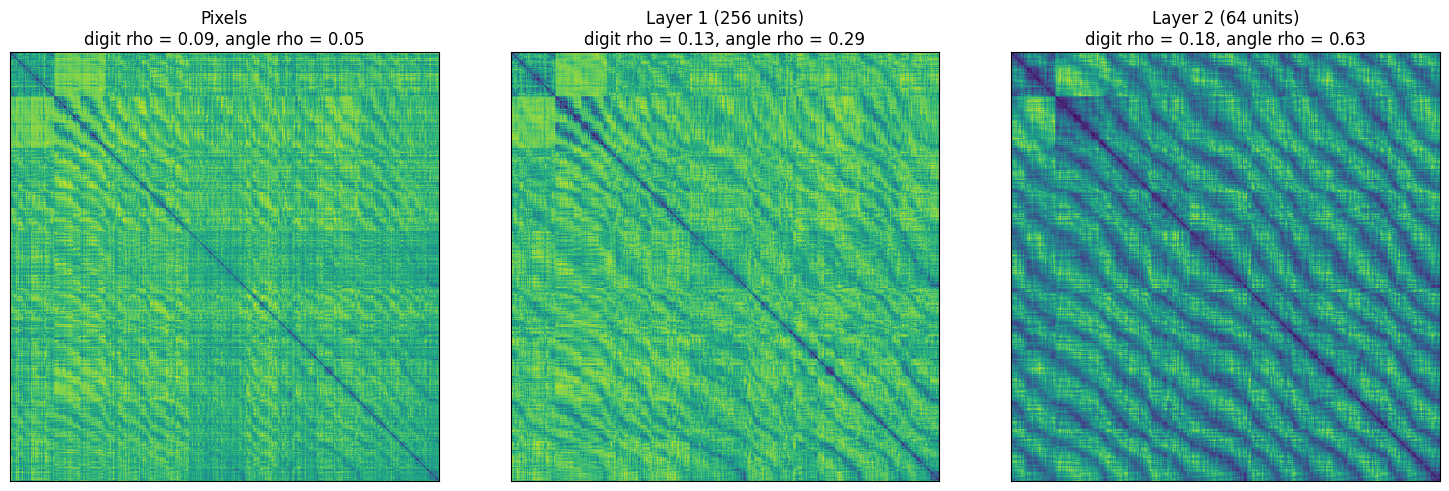

Pixels vs Layer 1 (256 units): rho = 0.735
Pixels vs Layer 2 (64 units): rho = 0.257
Layer 1 (256 units) vs Layer 2 (64 units): rho = 0.590
Layer 1 (256 units) PCs for 90% variance: 78
Layer 2 (64 units) PCs for 90% variance: 15


In [22]:
sub = np.random.choice(len(y), 600, replace=False)
sub = sub[np.lexsort((angle[sub], y[sub]))]
iu = np.triu_indices(len(sub), 1)
digit_model = (y[sub][:, None] != y[sub][None, :]).astype(float)
d = np.abs(angle[sub][:, None] - angle[sub][None, :])
angle_model = np.minimum(d, 360 - d)

def rdm(a):
    return 1 - np.corrcoef(a)

rdms = {'Pixels': rdm(X.flatten(1).numpy()[sub])}
rdms.update({name: rdm(a[sub]) for name, a in layers.items()})
fig, ax = plt.subplots(1, 3, figsize=(15, 4.8), layout='constrained')
for i, (name, R) in enumerate(rdms.items()):
    rho_d = spearmanr(R[iu], digit_model[iu])[0]
    rho_a = spearmanr(R[iu], angle_model[iu])[0]
    ax[i].imshow(R, cmap='viridis')
    ax[i].set(title=f'{name}\ndigit rho = {rho_d:.2f}, angle rho = {rho_a:.2f}', xticks=[], yticks=[])
    print(f'{name:22s} digit model rho = {rho_d:.3f}   angle model rho = {rho_a:.3f}')
plt.show()
names = list(rdms)
for i in range(3):
    for j in range(i + 1, 3):
        print(f'{names[i]} vs {names[j]}: rho = {spearmanr(rdms[names[i]][iu], rdms[names[j]][iu])[0]:.3f}')
for name, a in layers.items():
    print(name, 'PCs for 90% variance:', np.searchsorted(np.cumsum(PCA().fit(a).explained_variance_ratio_), 0.9) + 1)

## What changed from layer 1 to layer 2?
- **Rotation gets thrown away.** Layer 1 units are tuned to rotation angle, and each one prefers a narrow range of angles (angle selectivity 0.33). Layer 2 units are mostly flat across angle (0.11). Angle explains 7.7% of a layer 1 unit's variance but only 1.6% in layer 2, and the RDM's match to the angle model drops from 0.09 to 0.00.
- **Digit becomes the main structure.** Digit explains 52% of a layer 2 unit's variance, up from 18% in layer 1. The RDM matches the digit category model better (rho 0.23 to 0.43), and t-SNE splits layer 2 into clean digit clusters.
- **Single units don't get sharper.** Digit selectivity barely changes (0.45 vs 0.44). The change comes from units ignoring rotation, not from units becoming better digit detectors.
- **Compression:** layer 2 needs 9 PCs for 90% of the variance, compared with 62 for layer 1.
- **Linear vs nonlinear:** PCA only partly separates digits in either layer, while t-SNE shows clear clusters in layer 2. Much of the digit structure is nonlinear, so 2 linear dimensions miss it.
- **Overall:** the network applies a nonlinear (ReLU) transformation that removes a nuisance variable (rotation) and keeps the variable it was trained on (digit). The geometry moves step by step away from the pixels (RDM similarity with pixels: 0.72 for layer 1, 0.27 for layer 2).
- **Compared with unrotated MNIST:** accuracy drops from 95.9% to 90.1%, and both layers match the digit model less well (0.23 and 0.43, vs 0.41 and 0.49 before), because rotation scrambles the pixels.